In [25]:
import rasterio
from rasterio.enums import Resampling
from rasterio.warp import calculate_default_transform, reproject
from rasterio.transform import from_origin
import numpy as np
import geopandas as gpd
from shapely.geometry import Point
from shapely.geometry import box
import random
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
from scipy.stats import pearsonr
from sklearn.metrics import r2_score
import pandas as pd
import numpy as np
import rioxarray as rxr

c:\Users\minyu\.conda\envs\ICESAT_env\lib\site-packages\cupy\_environment.py:215: UserWarning: CUDA path could not be detected. Set CUDA_PATH environment variable if CuPy fails to load.
  warnings.warn(


In [19]:
year = 2020
path = f'G:\ICESat-2\Region2_map\Henber_map\A{year}\A_Henber_30m_{year}_new10_valid.shp'
k = gpd.read_file(path)
k.columns

Index(['Unnamed_ 0', 'distance', 'mean_heigh', 'mean_lon', 'mean_lat', 'OSGM',
       'OH', 'Strip_No', 'b1_FB6', 'b2_FB6', 'b3_FB6', 'b4_FB6', 'b5_FB6',
       'b6_FB6', 'b7_FB6', 'LULC', 'Ref_dem', 'geometry'],
      dtype='object')

In [40]:
year = 2019

validation_sample_paths_2019 = [
    # A_Thames_30m_2019_new10.shp

    f'H:\ICESat-2\Region1_map\Thames_map\A{year}\A_Thames_30m_{year}_new10_valid_kk.shp', #3676
    f'H:\ICESat-2\Region2_map\Henber_map\A{year}\A_Henber_30m_{year}_new10_valid_kk.shp', #1006
    f'H:\ICESat-2\Region2_map\wash_bay_map\A{year}\A_wash_bay_30m_{year}_new10_valid_kk.shp', #1662
    f'H:\ICESat-2\Region3_map\Region3b1_map\A{year}\A_Region3b1_30m_{year}_new10_valid_kk.shp',#387
    f'H:\ICESat-2\Region4_map\Ribble_map\A{year}\A_Ribble_30m_{year}_new10_valid_kk.shp',#2279
    f'H:\ICESat-2\Region4_map\Ribble1_map\A2019\A_Ribble1_30m_2019_new10_valid.shp',#2279
    f'H:\ICESat-2\Region4_map\Solway_map\A{year}\A_Solway_30m_{year}_new10_valid_kk.shp', #510
    f'H:\ICESat-2\Region4_map\Morecambe_map\A{year}\A_Morecambe_30m_{year}_new10_valid_kk.shp',#6424
    # f'G:\ICESat-2\Region4_map\Severn_map\A{year}\A_Severn_30m_{year}_new10_valid_kk.shp',#124
    
]


year = 2020
validation_sample_paths_2020 = [
    # A_Thames_30m_2019_new10.shp
    f'H:\ICESat-2\Region1_map\Thames_map\A{year}\A_Thames_30m_{year}_new10_valid_kk.shp', #3676
    f'H:\ICESat-2\Region2_map\Henber_map\A{year}\A_Henber_30m_{year}_new10_valid_kk.shp', #1006
    f'H:\ICESat-2\Region2_map\wash_bay_map\A{year}\A_wash_bay_30m_{year}_new10_valid_kk.shp', #1662
    f'H:\ICESat-2\Region4_map\Ribble_map\A{year}\A_Ribble_30m_{year}_new10_valid.shp',#2279
    f'H:\ICESat-2\Region4_map\Ribble1_map\A{year}\A_Ribble1_30m_{year}_new10_valid.shp',#2279
    f'H:\ICESat-2\Region4_map\Solway_map\A{year}\A_Solway_30m_{year}_new10_valid_kk.shp', #510
    f'H:\ICESat-2\Region4_map\Morecambe_map\A{year}\A_Morecambe_30m_{year}_new10_valid_kk.shp',#6424
    f'H:\ICESat-2\Region4_map\Severn_map\A{year}\A_Severn_30m_{year}_new10_valid_kk.shp',#124
    f'H:\ICESat-2\Region3_map\Region3c_map\A{year}\A_Region3c_30m_{year}_new10_kk.shp'
    #f'G:\ICESat-2\Region4_map\Parrett_map\A2020\A_Parrett_30m_2020_new10.shp'   
]

year = 2021
validation_sample_paths_2021 = [
    # A_Thames_30m_2019_new10.shp

    
    f'H:\ICESat-2\Region1_map\Thames_map\A{year}\A_Thames_30m_{year}_new10_valid_kk.shp', #3676 1 
    f'H:\ICESat-2\Region2_map\Henber_map\A{year}\A_Henber_30m_{year}_new10_valid_kk.shp', #1006 2 
    f'H:\ICESat-2\Region2_map\wash_bay_map\A{year}\A_wash_bay_30m_{year}_new10_valid_kk.shp', #1662 3 
    f'H:\ICESat-2\Region3_map\Region3b1_map\A{year}\A_Region3b1_30m_{year}_new10_valid_kk.shp',#387 4
    'H:\ICESat-2\Region3_map\Region3c_map\A2021\A_Region3c_30m_2021_new10_kk.shp', #5
    f'H:\ICESat-2\Region4_map\Ribble_map\A{year}\A_Ribble_30m_{year}_new10_valid.shp',#Dee 6
    f'H:\ICESat-2\Region4_map\Ribble1_map\A2021\A_Ribble1_30m_2021_new10_valid.shp',# ribble  7 
    f'H:\ICESat-2\Region4_map\Solway_map\A{year}\A_Solway_30m_{year}_new10_valid.shp', #510 8
    f'H:\ICESat-2\Region4_map\Morecambe_map\A{year}\A_Morecambe_30m_{year}_new10_valid_kk.shp',#6424 9
    'H:\ICESat-2\Region4_map\Region4b_map\A2021\A_Region4b_30m_2021_new10_valid.shp' #10

]

year = 2022
validation_sample_paths_2022 = [
    # A_Thames_30m_2019_new10.shp
    f'H:\ICESat-2\Region1_map\Thames_map\A{year}\A_Thames_30m_{year}_new10_valid_kk.shp', #3676 1
    f'H:\ICESat-2\Region2_map\Henber_map\A{year}\A_Henber_30m_{year}_new10_valid_kk.shp', #1006 2
    f'H:\ICESat-2\Region2_map\wash_bay_map\A{year}\A_wash_bay_30m_{year}_new10_valid_kk.shp', #1662 3 
    f'H:\ICESat-2\Region3_map\Region3b1_map\A{year}\A_Region3b1_30m_{year}_new10_valid_kk.shp',#387 4
    f'H:\ICESat-2\Region3_map\Region3c_map\A2022\A_Region3c_30m_2022_new10_kk.shp', # 5
    f'H:\ICESat-2\Region4_map\Ribble1_map\A{year}\A_Ribble1_30m_{year}_new10_valid.shp',#2279 6 
    f'H:\ICESat-2\Region4_map\Ribble_map\A{year}\A_Ribble_30m_{year}_new10_valid.shp',#Dee 7 
    f'H:\ICESat-2\Region4_map\Solway_map\A{year}\A_Solway_30m_{year}_new10_valid_kk.shp', #510 8 
    f'H:\ICESat-2\Region4_map\Morecambe_map\A{year}\A_Morecambe_30m_{year}_new10_valid_kk.shp',#6424 9
    f'H:\ICESat-2\Region4_map\Severn_map\A{year}\A_Severn_30m_{year}_new10_valid_kk.shp',#124 10
    f"H:\ICESat-2\Region5_map\Region5b_map\A2022\A_Region5b_30m_2022_new10_valid_kk.shp", # 11
    'H:\ICESat-2\Region4_map\Region4c_map\A2022\A_Region4c_30m_2022_new10_valid.shp' #12
    # 
]

year = 2023
validation_sample_paths_2023 = [
    # A_Thames_30m_2019_new10.shp


    f'H:\ICESat-2\Region1_map\Thames_map\A{year}\A_Thames_30m_{year}_new10_valid_kk.shp', #3676
    f'H:\ICESat-2\Region2_map\Henber_map\A{year}\A_Henber_30m_{year}_new10_valid_kk.shp', #1006
    f'H:\ICESat-2\Region2_map\wash_bay_map\A{year}\A_wash_bay_30m_{year}_new10_valid_kk.shp', #1662
    f'H:\ICESat-2\Region3_map\Region3b1_map\A{year}\A_Region3b1_30m_{year}_new10_valid_kk.shp',#387
    f'H:\ICESat-2\Region4_map\Ribble_map\A{year}\A_Ribble_30m_{year}_new10_valid.shp',#2279
    f'H:\ICESat-2\Region4_map\Ribble1_map\A{year}\A_Ribble1_30m_{year}_new10_valid.shp',#2279
    f'H:\ICESat-2\Region4_map\Solway_map\A{year}\A_Solway_30m_{year}_new10_valid_kk.shp', #510
    f'H:\ICESat-2\Region4_map\Morecambe_map\A{year}\A_Morecambe_30m_{year}_new10_valid_kk.shp',#6424
    f'H:\ICESat-2\Region4_map\Severn_map\A{year}\A_Severn_30m_{year}_new10_valid_kk.shp',#124
    
    #f'G:\ICESat-2\Region4_map\Parrett_map\A2020\A_Parrett_30m_2020_new10.shp'   
]

year = 2024
validation_sample_paths_2024 = [

    f'H:\ICESat-2\Region1_map\Thames_map\A{year}\A_Thames_30m_{year}_new10_valid.shp', #1701
    f'H:\ICESat-2\Region2_map\Henber_map\A{year}\A_Henber_30m_{year}_new10_valid.shp', #1006
    f'H:\ICESat-2\Region2_map\wash_bay_map\A{year}\A_wash_bay_30m_{year}_new10_valid.shp', #1662

]


# 读取并提取指定列
# year = 2021
# gdf_list = []
# for path in validation_sample_paths_2021:
#     gdf = gpd.read_file(path)
#     gdf_selected = gdf[['Ref_dem', 'OH']]  # 只保留所需字段
#     gdf_list.append(gdf_selected)

# # 合并所有 GeoDataFrame
# merged_gdf = pd.concat(gdf_list, ignore_index=True)


gdf_list = []
validation_sample_paths_all = [validation_sample_paths_2019, validation_sample_paths_2020,
                               validation_sample_paths_2021, validation_sample_paths_2022,
                               validation_sample_paths_2023, validation_sample_paths_2024]

for validation_sample_paths  in validation_sample_paths_all:
    for path in validation_sample_paths:
    
        gdf = gpd.read_file(path)
        gdf_selected = gdf[['Ref_dem', 'OH']]  # 只保留所需字段
        gdf_list.append(gdf_selected)
# 合并所有 GeoDataFrame
merged_gdf_ICESat = pd.concat(gdf_list, ignore_index=True)



In [ ]:
len(merged_gdf_ICESat)
# z = merged_gdf_ICESat[['Ref_dem', 'OH']]
z = merged_gdf_ICESat[['Ref_dem', 'OH']]
mask = (z['OH'] != 0) | (z['Ref_dem'] != 6) | (z['Ref_dem'] != -999)
z = z[mask]
z = z[z != -999]
z = z[z != 6]
z = z[z != 0]
z = z.dropna()
z

R² = 0.938, MAE = 0.184, MSB = 0.041, RMSE = 0.379, N = 46978


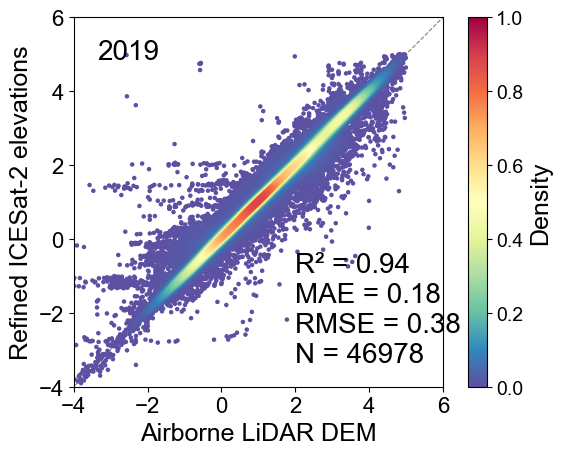

In [5]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import gaussian_kde
from sklearn.metrics import r2_score

plt.rcParams['font.family'] = 'Arial'  # ✅ 全局字体设为 Arial

# ------------------- 你的计算部分 -------------------
year = 2019
gdf_list = []
for path in validation_sample_paths_2019:
    gdf = gpd.read_file(path)
    gdf_selected = gdf[['Ref_dem', 'OH']]  # 只保留所需字段
    gdf_list.append(gdf_selected)

# 合并所有 GeoDataFrame
# merged_gdf = pd.concat(gdf_list, ignore_index=True)

# z = merged_gdf[['Ref_dem', 'OH']]
z = merged_gdf_ICESat[['Ref_dem', 'OH']]
mask = (z['OH'] != 0) | (z['Ref_dem'] != 6) | (z['Ref_dem'] != -999)
z = z[mask]
z = z[z != -999]
z = z[z != 6]
z = z[z != 0]
z = z.dropna()

x = np.array(z['Ref_dem'])  # y_true
y = np.array(z['OH'])       # y_pred

R2 = r2_score(x, y)
MAE = np.mean(np.abs(y - x))
MSB = np.mean((y - x))
RMSE = np.sqrt(np.mean((y - x) ** 2))
num = int(len(x))

print(f"R² = {R2:.3f}, MAE = {MAE:.3f}, MSB = {MSB:.3f}, RMSE = {RMSE:.3f}, N = {num}")

# ------------------- 绘图部分 -------------------
xy = np.vstack([x, y])
z = gaussian_kde(xy)(xy)

idx = z.argsort()
x_sorted, y_sorted, z_sorted = x[idx], y[idx], z[idx]

fig, ax = plt.subplots()
textstr = f"R² = {R2:.2f}\nMAE = {MAE:.2f}\nRMSE = {RMSE:.2f}\nN = {num}"

ax.text(
        0.60, 0.05,
        textstr,
        transform=ax.transAxes,
        fontsize=20,
        verticalalignment='bottom',
        linespacing=1.2   # 默认是 1.0，调大就会加宽行间距
)

name = year

# ax.text(0.05, 0.95, textstr, transform=ax.transAxes, fontsize=18,
#         verticalalignment='top')
# ax.text(0.95, 0.05, textstr, transform=ax.transAxes, fontsize=20,
#         verticalalignment='bottom', horizontalalignment='right')
ax.text(0.23, 0.87, name, transform=ax.transAxes, fontsize=20,
        verticalalignment='bottom', horizontalalignment='right')

ax.set_xlabel('Airborne LiDAR DEM', fontsize=18)
ax.set_ylabel('Refined ICESat-2 elevations', fontsize=18)
ax.plot([-6, 6], [-6, 6], color='gray', linestyle='--', linewidth=0.8, zorder=1)

sc = ax.scatter(x_sorted, y_sorted, c=z_sorted, vmin=0, vmax=1, s=5, cmap='Spectral_r', zorder=2)
cbar = plt.colorbar(sc)
cbar.ax.tick_params(labelsize=14) 
cbar.set_label("Density", fontsize=18)
ax.set_xlim(-4, 5)
ax.set_ylim(-4, 5)

tick_interval = 2
ticks = np.arange(-4, 5 + tick_interval, tick_interval)
ax.set_xticks(ticks)
ax.set_yticks(ticks)

ax.set_aspect('equal')
ax.tick_params(axis='both', labelsize=16)

plt.show()
plt.close()


In [2]:
path = 'G:\ICESat-2\Region4_map\Region4c_map\A2022\A_Region4c_30m_2022_new10_valid.shp'



def draw_plot(path, output_dir, name, vmax):
        
        merged_gdf = gpd.read_file(path)
        z = merged_gdf[['Ref_dem', 'OH']]

        mask = (z['OH'] != 0) | (z['Ref_dem'] != 6) | (z['Ref_dem'] != -999)
        z = z[mask]
        z = z[z != -999]
        z = z[z != 6]
        z = z[z != 0]
        z = z.dropna()

        x = np.array(z['Ref_dem'])  # y_true
        y = np.array(z['OH'])       # y_pred

        R2 = r2_score(x, y)
        MAE = np.mean(np.abs(y - x))
        MSB = np.mean((y - x))
        RMSE = np.sqrt(np.mean((y - x) ** 2))
        num = int(len(x))

        print(f"R² = {R2:.3f}, MAE = {MAE:.3f}, MSB = {MSB:.3f}, RMSE = {RMSE:.3f}, N = {num}")

        # ------------------- 绘图部分 -------------------
        xy = np.vstack([x, y])
        z = gaussian_kde(xy)(xy)

        idx = z.argsort()
        x_sorted, y_sorted, z_sorted = x[idx], y[idx], z[idx]

        fig, ax = plt.subplots()
        textstr = f"R² = {R2:.2f}\nMAE = {MAE:.2f}\nRMSE = {RMSE:.2f}\nN = {num}"

        ax.text(
                0.50, 0.05,
                textstr,
                transform=ax.transAxes,
                fontsize=22,
                verticalalignment='bottom',
                linespacing=1.2   # 默认是 1.0，调大就会加宽行间距
        )

        name = name

        # ax.text(0.05, 0.95, textstr, transform=ax.transAxes, fontsize=18,
        #         verticalalignment='top')
        # ax.text(0.95, 0.05, textstr, transform=ax.transAxes, fontsize=20,
        #         verticalalignment='bottom', horizontalalignment='right')
        ax.text(0.05, 0.87, name, transform=ax.transAxes, fontsize=22,
                verticalalignment='bottom', horizontalalignment='left')

        ax.set_xlabel('Airborne LiDAR DEM', fontsize=18)
        ax.set_ylabel('Refined ICESat-2', fontsize=18)
        ax.plot([-6, 6], [-6, 6], color='gray', linestyle='--', linewidth=0.8, zorder=1)

        sc = ax.scatter(x_sorted, y_sorted, c=z_sorted, vmin=0, vmax=vmax, s=5, cmap='Spectral_r', zorder=2)
        cbar = plt.colorbar(sc)
        cbar.ax.tick_params(labelsize=14) 
        cbar.set_label("Density", fontsize=18)
        ax.set_xlim(-4, 5)
        ax.set_ylim(-4, 5)

        tick_interval = 2
        ticks = np.arange(-4, 5 + tick_interval, tick_interval)
        ax.set_xticks(ticks)
        ax.set_yticks(ticks)

        ax.set_aspect('equal')
        ax.tick_params(axis='both', labelsize=16)

        plt.savefig(output_dir, dpi=300, bbox_inches='tight')  # 保存图像
        plt.show()
        plt.close()
        
def sample_raster_to_gdf(validation_point_path, raster_path, column_name):
    
    gdf = gpd.read_file(validation_point_path)

    with rasterio.open(raster_path) as src:
        if gdf.crs != src.crs:
            gdf = gdf.to_crs(src.crs)
        coords = [(point.x, point.y) for point in gdf.geometry]
        values = [v[0] if v else None for v in src.sample(coords)]
        gdf[column_name] = values
        
    gdf.to_file(validation_point_path)
    return gdf

R² = 0.959, MAE = 0.096, MSB = 0.039, RMSE = 0.307, N = 232


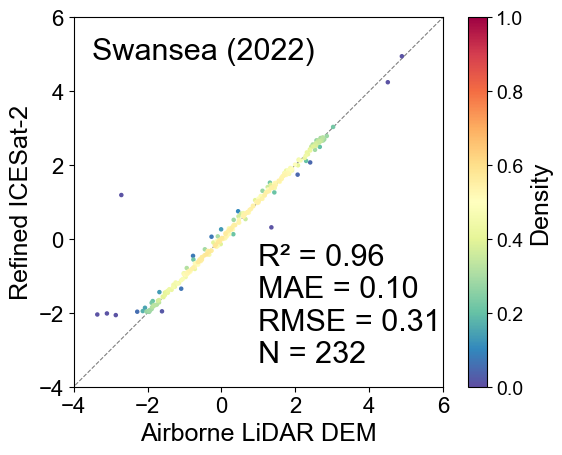

In [98]:
import os
region = 'Region4'
location = 'Severn'
location2 = 'Severn'

year_list = [2019, 2020, 2021, 2022,2023, 2024]
year_list = [2020, 2021, 2022]
year_list = [2022]
# year_list = [2019]
# year_list = [20]

for year in year_list:
    

    validation_sample_path = f'G:\ICESat-2\{region}_map\{location}_map\A{year}/A_{location}_30m_{year}_new10_kk.shp'
    validation_sample_path = f'G:\ICESat-2\Region4_map\Severn_map\A{year}\A_Severn_30m_{year}_new10_valid_kk.shp'
    # validation_sample_path = f"G:\ICESat-2\{region}_map\{location}_map\A{year}\A_{location}_30m_{year}_new10.shp"
    # ref_dem_path = f"G:\DTM_ref\{location2}\{location2}_{year}\{location2}_masked_{year}.tif"
    # gdf = sample_raster_to_gdf(validation_sample_path, ref_dem_path, 'Ref_dem')
    plot_output_path = f"G:/ICESat-2/Refined_ICESat_validation4/Swansea/A_Swansea_{year}_new9.png"
    plot_name = f'Swansea ({year})'
    
    output_dir = os.path.dirname(plot_output_path)
    os.makedirs(output_dir, exist_ok=True)
    # plot_name = f'{location} ({year})'
    
    
    
    # gdf = sample_raster_to_gdf(validation_sample_path, ref_dem_path_new, 'Refer_dem_30')
    draw_plot(validation_sample_path, plot_output_path, plot_name, 1)
    

In [29]:
# 所有路径放入列表中
year = 2019
validation_sample_paths_2019 = [
    f'H:\ICESat-2\Region1_map\Thames1_map\A{year}\Thames1_{year}_sample_points_final.shp',
    f'H:\ICESat-2\Region2_map\Henber_map\A{year}\Henber_{year}_sample_points_final.shp',
    f'H:\ICESat-2\Region2_map\wash_bay_map\A{year}\wash_bay_{year}_sample_points_final.shp',
    f'H:\ICESat-2\Region3_map\Region3b1_map\A{year}\Region3b1_{year}_sample_points_final.shp',
    f'H:\ICESat-2\Region4_map\Ribble1_map\A{year}\Ribble1_{year}_sample_points_final.shp',
    f'H:\ICESat-2\Region4_map\Solway_map\A{year}\Solway_{year}_sample_points_final.shp',
    f'H:\ICESat-2\Region4_map\Morecambe_map\A{year}\Morecambe_{year}_sample_points_final.shp',
    f'H:\ICESat-2\Region4_map\Ribble_map\A{year}\Ribble_{year}_sample_points.shp'
]

year = 2020
validation_sample_paths_2020 = [
    f'H:\ICESat-2\Region1_map\Thames1_map\A{year}\Thames1_{year}_sample_points_final.shp',
    f'H:\ICESat-2\Region2_map\Henber_map\A{year}\Henber_{year}_sample_points_final.shp',
    f'H:\ICESat-2\Region2_map\wash_bay_map\A{year}\wash_bay_{year}_sample_points_final.shp',
    f'H:\ICESat-2\Region4_map\Ribble1_map\A{year}\Ribble1_{year}_sample_points_final.shp',
    f'H:\ICESat-2\Region4_map\Solway_map\A{year}\Solway_{year}_sample_points_final.shp',
    f'H:\ICESat-2\Region4_map\Morecambe_map\A{year}\Morecambe_{year}_sample_points_final.shp',
    f'H:\ICESat-2\Region4_map\Parrett_map\A2020\Parrett_2020_sample_points_final.shp',
    f"H:\ICESat-2\Region3_map\Region3c_map\A2020\Region3c_2020_sample_points_final.shp",
    f'H:\ICESat-2\Region4_map\Ribble_map\A{year}\Ribble_{year}_sample_points.shp'
]

year = 2021
validation_sample_paths_2021 = [
    f'H:\ICESat-2\Region1_map\Thames1_map\A{year}\Thames1_{year}_sample_points_final.shp',
    f'H:\ICESat-2\Region2_map\Henber_map\A{year}\Henber_{year}_sample_points_final.shp',
    f'H:\ICESat-2\Region2_map\wash_bay_map\A{year}\wash_bay_{year}_sample_points_final.shp',
    f'H:\ICESat-2\Region3_map\Region3b1_map\A{year}\Region3b1_{year}_sample_points_final.shp',
    f'H:\ICESat-2\Region4_map\Ribble1_map\A{year}\Ribble1_{year}_sample_points_final.shp',
    f'H:\ICESat-2\Region4_map\Solway_map\A{year}\Solway_{year}_sample_points_final.shp',
    f'H:\ICESat-2\Region4_map\Morecambe_map\A{year}\Morecambe_{year}_sample_points_final.shp',
    f'H:\ICESat-2\Region4_map\Araw_map\A2021\Araw_2021_sample_points_final.shp',
    f'H:\ICESat-2\Region4_map\Ribble_map\A{year}\Ribble_{year}_sample_points.shp',
    f"H:\ICESat-2\Region3_map\Region3c_map\A{year}\Region3c_{year}_sample_points_final.shp",
]

year = 2022
validation_sample_paths_2022 = [
    f'H:\ICESat-2\Region1_map\Thames1_map\A{year}\Thames1_{year}_sample_points_final.shp',
    f'H:\ICESat-2\Region2_map\Henber_map\A{year}\Henber_{year}_sample_points_final.shp',
    f'H:\ICESat-2\Region2_map\wash_bay_map\A{year}\wash_bay_{year}_sample_points_final.shp',
    f'H:\ICESat-2\Region3_map\Region3b1_map\A{year}\Region3b1_2022_sample_points_final.shp',#Region3b1_2022_sample_points_final
    f'H:\ICESat-2\Region4_map\Ribble1_map\A{year}\Ribble1_{year}_sample_points_final.shp',
    f'H:\ICESat-2\Region4_map\Solway_map\A{year}\Solway_{year}_sample_points_final.shp',
    f'H:\ICESat-2\Region4_map\Morecambe_map\A{year}\Morecambe_{year}_sample_points_final.shp',
    f'H:\ICESat-2\Region4_map\Baglan_map\A2022\Baglan_2022_sample_points_final.shp',# SWansea Bay
    f'H:\ICESat-2\Region4_map\AfonDyfi_map\A2022\AfonDyfi_2022_sample_points_final.shp',
    f'H:\ICESat-2\Region4_map\Ribble_map\A{year}\Ribble_{year}_sample_points.shp', #Dee
    f"H:\ICESat-2\Region3_map\Region3c_map\A{year}\Region3c_{year}_sample_points.shp",
    f"H:\ICESat-2\Region5_map\Carmarthen_map\A2022\Carmarthen_2022_sample_points_final.shp",
    
]

year = 2023
validation_sample_paths_2023 = [
    f'H:\ICESat-2\Region1_map\Thames1_map\A{year}\Thames1_{year}_sample_points_final.shp',
    f'H:\ICESat-2\Region2_map\Henber_map\A{year}\Henber_{year}_sample_points_final.shp',
    f'H:\ICESat-2\Region2_map\wash_bay_map\A{year}\wash_bay_{year}_sample_points_final.shp',
    f'H:\ICESat-2\Region3_map\Region3b1_map\A{year}\Region3b1_{year}_sample_points_final.shp',
    f'H:\ICESat-2\Region4_map\Ribble1_map\A{year}\Ribble1_{year}_sample_points_final.shp',
    f'H:\ICESat-2\Region4_map\Solway_map\A{year}\Solway_{year}_sample_points_final.shp',
    f'H:\ICESat-2\Region4_map\Morecambe_map\A{year}\Morecambe_{year}_sample_points_final.shp',
    f'H:\ICESat-2\Region4_map\Parrett_map\A2023\Parrett_2023_sample_points_final.shp',
    f'H:\ICESat-2\Region4_map\Ribble_map\A{year}\Ribble_{year}_sample_points.shp', #Dee
]

year = 2024
validation_sample_paths_2024 = [

    f'H:\ICESat-2\Region2_map\wash_bay_map\A{year}\wash_bay_{year}_sample_points_final.shp',
    f'H:\ICESat-2\Region1_map\Thames1_map\A{year}\Thames1_{year}_sample_points_final.shp',
    f'H:\ICESat-2\Region2_map\Henber_map\A{year}\Henber_{year}_sample_points_final.shp',
    
]


# 读取并提取指定列
# gdf_list = []
# for path in validation_sample_paths_2019:
#     gdf = gpd.read_file(path)
#     gdf_selected = gdf[['Refer_dem', 'DEM_new9']]  # 只保留所需字段
#     gdf_list.append(gdf_selected)

# # 合并所有 GeoDataFrame
# merged_gdf = pd.concat(gdf_list, ignore_index=True)


#读取并提取指定列
gdf_list = []
for path in validation_sample_paths_2020:
    gdf = gpd.read_file(path)
    gdf_selected = gdf[['Refer_dem', 'DEM_new9']]  # 只保留所需字段
    gdf_list.append(gdf_selected)

# 合并所有 GeoDataFrame
merged_gdf = pd.concat(gdf_list, ignore_index=True)

gdf_list = []
validation_sample_paths_all = [validation_sample_paths_2019, validation_sample_paths_2020,
                               validation_sample_paths_2021, validation_sample_paths_2022,
                               validation_sample_paths_2023, validation_sample_paths_2024]

for validation_sample_paths  in validation_sample_paths_all:
    for path in validation_sample_paths:
    
        gdf = gpd.read_file(path)
        gdf_selected = gdf[['Refer_dem', 'DEM_new9']]  # 只保留所需字段
        gdf_list.append(gdf_selected)
# 合并所有 GeoDataFrame
merged_gdf_DEM = pd.concat(gdf_list, ignore_index=True)




In [39]:
merged_gdf_DEM.columns

Index(['Refer_dem', 'DEM_new9'], dtype='object')

In [ ]:
plt.rcParams['font.family'] = 'Arial' 
z = merged_gdf_DEM[['Refer_dem', 'DEM_new9']]
mask = (z['DEM_new9'] != 0) | (z['Refer_dem'] !=6) | (z['Refer_dem'] != -999)
z = z[mask]
z = z[z!=-999]
z = z[z!=6]
z = z[z!=0]
z = z.dropna()
x = np.array(z['Refer_dem']) #y_true
y = np.array(z['DEM_new9']) # y_pred
xy_lim_range = [-4, 6]
    # R, _ = pearsonr(y, x)
R2 = r2_score(x, y) #r2_score(y_true, y_pred)
MAE = np.mean(np.abs(y-x))
MSB = np.mean((y-x))
RMSE = np.sqrt(np.mean((y-x)**2))
num = int(len(x))

print(f"R² = {R2:.3f}, MAE = {MAE:.3f}, MSB = {MSB:.3f}, RMSE = {RMSE:.3f}, N = {num}")
    
xy = np.vstack([x,y])  #  将两个维度的数据叠加
z = gaussian_kde(xy)(xy)  # 建立概率密度分布，并计算每个样本点的概率密度

    # Sort the points by density, so that the densest points are plotted last
idx = z.argsort()
x_sorted, y_sorted, z_sorted = x[idx], y[idx], z[idx]

fig, ax = plt.subplots()
textstr = f"R² = {R2:.2f}\nMAE = {MAE:.2f}\nRMSE = {RMSE:.2f}\nN = {num}"
name = year#f'{location2} ({year})'

# ax.text(0.05, 0.95, textstr, transform = ax.transAxes, fontsize = 16, verticalalignment = 'top')
ax.text(0.95, 0.05, textstr, transform=ax.transAxes, fontsize=20, verticalalignment='bottom', horizontalalignment='right')

ax.set_xlabel('Reference dem', fontsize = 18)
ax.set_ylabel('Retrieved dem', fontsize = 18)
ax.plot([-6, 6], [-6, 6], color='gray', linestyle='--', linewidth=0.8, zorder=1)

sc = plt.scatter(x_sorted, y_sorted, c=z_sorted, s=5, vmin=0, vmax=0.5, cmap='Spectral_r', zorder=2)
cbar = plt.colorbar(sc)

    # plt.scatter(x, y,c=z, s=2,cmap='Spectral_r') # c表示标记的颜色
    # plt.colorbar()

ax.set_xlim(-4, 5)
ax.set_ylim(-4, 5)

# 设置一致的刻度间隔（例如每 1 单位一个刻度）
tick_interval = 2
ticks = np.arange(-4, 5 + tick_interval, tick_interval)
ax.set_xticks(ticks)
ax.set_yticks(ticks)

# 设置等比例显示
ax.set_aspect('equal')

ax.tick_params(axis='both', labelsize=16)
        
# plt.savefig(output_path, dpi=300, bbox_inches='tight')  # 保存图像
plt.show()
plt.close()

In [36]:
merged_gdf_DEM.columns

Index(['Refer_dem', 'DEM_new9'], dtype='object')

In [50]:
value_list = [-4, -3, -2, -1, 0, 1, 2, 3, 4, 5]

z = merged_gdf_DEM[['Refer_dem', 'DEM_new9']]
mask = (z['DEM_new9'] != 0) | (z['Refer_dem'] !=6) | (z['Refer_dem'] != -999)
z = z[mask]
z = z[z!=-999]
z = z[z!=6]
z = z[z!=0]
z = z.dropna()
print(len(z))
print('ICESat-2:')
for v in value_list:

    
    k = z[(z['Refer_dem'] < v+1) &(z['Refer_dem'] > v)]
    x = np.array(k['Refer_dem']) #y_true
    y = np.array(k['DEM_new9']) #
    num = len(k)
    RMSE = np.sqrt(np.mean((y-x)**2))
    MAE = np.mean(np.abs(y-x))
    print(f'num: {num}',f'range: [{v}, {v+1}], RMSE:', RMSE)
    # print(f'num: {num}',f'range: [{v}, {v+1}], MAE:', MAE)

101646
ICESat-2:
num: 617 range: [-4, -3], RMSE: 1.7722095164573064
num: 3745 range: [-3, -2], RMSE: 1.5144883829991487
num: 16260 range: [-2, -1], RMSE: 0.8575599960436786
num: 23252 range: [-1, 0], RMSE: 0.5860677480899343
num: 20347 range: [0, 1], RMSE: 0.48483428964792813
num: 16029 range: [1, 2], RMSE: 0.45530270285803043
num: 11471 range: [2, 3], RMSE: 0.5010912300254733
num: 8229 range: [3, 4], RMSE: 0.4591127840490172
num: 1477 range: [4, 5], RMSE: 0.6853018314579234
num: 0 range: [5, 6], RMSE: nan


c:\Users\minyu\.conda\envs\ICESAT_env\lib\site-packages\numpy\core\fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\minyu\.conda\envs\ICESAT_env\lib\site-packages\numpy\core\_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


In [ ]:
DEM_RMSE_list = [1.772, 1.514, 0.857, 0.586, 0.4848, 0.455, 0.501, 0.459, 0.6853]

In [49]:
value_list = [-4, -3, -2, -1, 0, 1, 2, 3, 4, 5]

z = merged_gdf_ICESat[['Ref_dem', 'OH']]
mask = (z['OH'] != 0) | (z['Ref_dem'] !=6) | (z['Ref_dem'] != -999)
z = z[mask]
z = z[z!=-999]
z = z[z!=6]
z = z[z!=0]
z = z.dropna()
print(len(z))
print('ICESat-2:')
for v in value_list:

    
    k = z[(z['Ref_dem'] < v+1) &(z['Ref_dem'] > v)]
    x = np.array(k['Ref_dem']) #y_true
    y = np.array(k['OH']) #
    num = len(k)
    RMSE = np.sqrt(np.mean((y-x)**2))
    MAE = np.mean(np.abs(y-x))
    print(f'num: {num}',f'range: [{v}, {v+1}], RMSE:', RMSE)
    # print(f'num: {num}',f'range: [{v}, {v+1}], MAE:', MAE)

46978
ICESat-2:
num: 121 range: [-4, -3], RMSE: 1.4427084353727886
num: 432 range: [-3, -2], RMSE: 1.4388747147096352
num: 2616 range: [-2, -1], RMSE: 0.6079665067526894
num: 7501 range: [-1, 0], RMSE: 0.3631245841991314
num: 10766 range: [0, 1], RMSE: 0.25407611945773956
num: 10301 range: [1, 2], RMSE: 0.2748092853995064
num: 8223 range: [2, 3], RMSE: 0.3596409945148983
num: 5650 range: [3, 4], RMSE: 0.33034356153707084
num: 1265 range: [4, 5], RMSE: 0.4366318526013491
num: 0 range: [5, 6], RMSE: nan


c:\Users\minyu\.conda\envs\ICESAT_env\lib\site-packages\numpy\core\fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\minyu\.conda\envs\ICESAT_env\lib\site-packages\numpy\core\_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


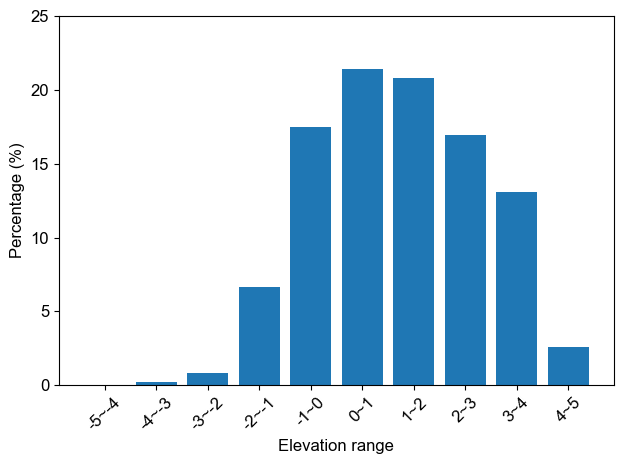

In [57]:
z = merged_gdf_ICESat[['Ref_dem', 'OH']]
mask = (z['OH'] != 0) | (z['Ref_dem'] !=6) | (z['Ref_dem'] != -999)
z = z[mask]
z = z[z!=-999]
z = z[z!=6]
z = z[z!=0]
z = z.dropna()

colors = np.linspace(0, 1, len(x))


value_list = [-4, -3, -2, -1, 0, 1, 2, 3, 4, 5]

z = merged_gdf_ICESat[['Ref_dem', 'OH']].copy()

# 统一转成一列数据（做直方图必须）
data = pd.concat([z['Ref_dem'], z['OH']], ignore_index=True)

# 去掉无效值
data = data[(data != -999) & (data != 6) & (data != 0)]
data = data.dropna()

bins = [-5, -4, -3, -2, -1, 0, 1, 2, 3, 4, 5]

counts, _ = np.histogram(data, bins=bins)

# 转百分比
percent = counts / counts.sum() * 100

fig, ax = plt.subplots()

ax.bar(range(len(percent)), percent, width=0.8)

ax.set_ylim(0, 25)
ax.set_ylabel('Percentage (%)')
ax.set_xlabel('Elevation range')

ax.set_xticks(range(len(percent)))
ax.set_xticklabels(['-5~-4','-4~-3','-3~-2','-2~-1','-1~0',
                     '0~1','1~2','2~3','3~4','4~5'],
                    rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
DEM_MAE_list = [1.5799, 1.180, 0.6079, 0.4195, 0.353, 0.332, 0.3643, 0.2993, 0.5367]
ICESAT_MAE_list = [0.860, 0.9330,  0.320, 0.183, 0.1326, 0.1481, 0.2049, 0.1642,  0.2271]

DEM_RMSE_list = [1.772, 1.514, 0.857, 0.586, 0.4848, 0.455, 0.501, 0.459, 0.6853]
ICESAT_RMSE_list = [1.442, 1.438,  0.607, 0.363, 0.254, 0.274, 0.3596,  0.3303,  0.4366]

In [ ]:
value_list = [-4, -3, -2, -1, 0, 1, 2, 3, 4, 5]

z = merged_gdf_DEM[['Refer_dem', 'DEM_new9']]
mask = (z['DEM_new9'] != 0) | (z['Refer_dem'] !=6) | (z['Refer_dem'] != -999)
z = z[mask]
z = z[z!=-999]
z = z[z!=6]
z = z[z!=0]
z = z.dropna()
print(len(z))
print('ICESat-2:')
for v in value_list:

    
    k = z[(z['Refer_dem'] < v+1) &(z['Refer_dem'] > v)]
    x = np.array(k['Refer_dem']) #y_true
    y = np.array(k['DEM_new9']) #
    num = len(k)
    RMSE = np.sqrt(np.mean((y-x)**2))
    MAE = np.mean(np.abs(y-x))
    #print(f'num: {num}',f'range: [{v}, {v+1}], RMSE:', RMSE)
    print(f'num: {num}',f'range: [{v}, {v+1}], MAE:', MAE)

In [ ]:
DEM_MAE_list = [1.5799, 1.180, 0.607, 0.419, 0.3535, 0.332, 0.364, 0.2993, 0.5367]

In [52]:
600 / 46173


0.012994607237996232

R² = 0.962, MAE = 0.089, MSB = 0.009, RMSE = 0.207, N = 2832


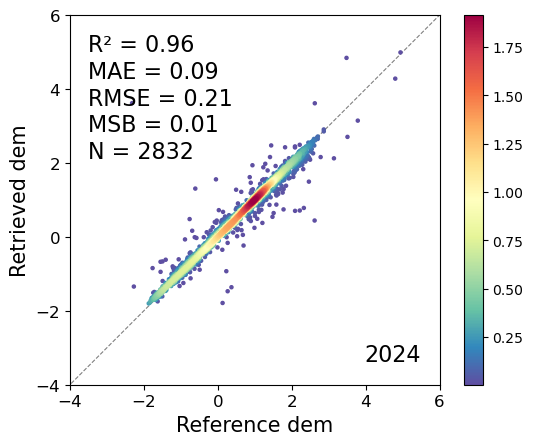

In [ ]:
DEM_RMSE_list = [1.7755, 1.5690, 0.8985, 0.5881, 0.4752, 0.4610, 0.4969, 0.4575, 0.686]

ICESat_RMSE_list = [ 1.2128, 1.2719, 0.8220, 0.47894, 0.3537, 0.28394, 0.3881, 0.3600, 0.429198]

C:\Users\minyu\AppData\Local\Temp\ipykernel_38920\2450122825.py:20: UserWarning: You passed a edgecolor/edgecolors ('k') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  plt.scatter(x[:9], y[:9], c=colors[:9], cmap="viridis", s=90, marker="x", edgecolor="k", label="Last 4 points")
C:\Users\minyu\AppData\Local\Temp\ipykernel_38920\2450122825.py:28: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "r--" (-> color='r'). The keyword argument will take precedence.
  plt.plot([min_val, max_val], [min_val, max_val], 'r--', color='gray',linewidth=1, label="1:1 line")


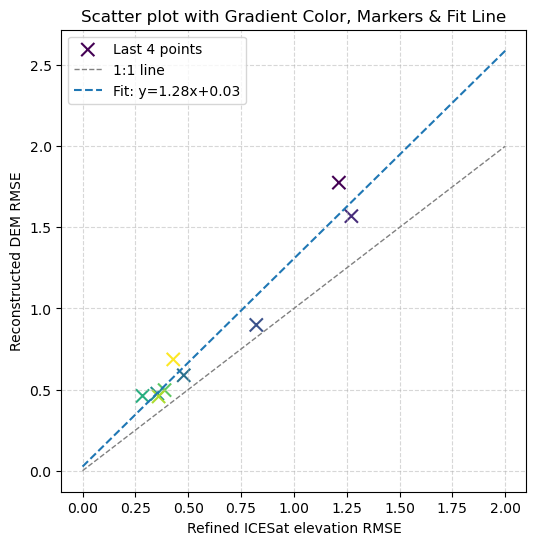

In [4]:
import matplotlib.pyplot as plt
import numpy as np

# 数据
DEM_RMSE_list = [1.7755, 1.5690, 0.8985, 0.5881, 0.4752, 0.4610, 0.4969, 0.4575, 0.686]
ICESat_RMSE_list = [1.2128, 1.2719, 0.8220, 0.47894, 0.3537, 0.28394, 0.3881, 0.3600, 0.429198]

x = np.array(ICESat_RMSE_list)
y = np.array(DEM_RMSE_list)

# 渐变颜色
colors = np.linspace(0, 1, len(x))

plt.figure(figsize=(6, 6))

# 前四个点: 圆点
# plt.scatter(x[:4], y[:4], c=colors[:4], cmap="viridis", s=90, marker="o", edgecolor="k", label="First 4 points")

# 后四个点: 叉号
plt.scatter(x[:9], y[:9], c=colors[:9], cmap="viridis", s=90, marker="x", edgecolor="k", label="Last 4 points")

# 第9个点(单独画)
#plt.scatter(x[8], y[8], c=[colors[8]], cmap="viridis", s=90, marker="D", edgecolor="k", label="Point 9")

# 添加1:1参考线
min_val = 0
max_val = 2
plt.plot([min_val, max_val], [min_val, max_val], 'r--', color='gray',linewidth=1, label="1:1 line")

# 线性拟合
coef = np.polyfit(x, y, 1)  # 拟合 y = a*x + b
poly1d_fn = np.poly1d(coef)
plt.plot([min_val, max_val], poly1d_fn([min_val, max_val]), '--', linewidth=1.5, label=f"Fit: y={coef[0]:.2f}x+{coef[1]:.2f}")

plt.xlabel("Refined ICESat elevation RMSE")
plt.ylabel("Reconstructed DEM RMSE")
plt.title("Scatter plot with Gradient Color, Markers & Fit Line")
plt.legend()

plt.grid(True, linestyle="--", alpha=0.5)
#plt.colorbar(plt.cm.ScalarMappable(cmap="viridis"), label="Point Index")
plt.show()


In [9]:
import rasterio
from rasterio.warp import reproject, Resampling
import numpy as np

# 文件路径
mask_path = r"H:\ICESat-2\Region2_map\wash_bay_map\A2022\wash_bay_2022_4_RF_FB6_new10_bys.tif"
target_path = r"H:\DTM_ref\Wash\Wash_2022\Wash_masked_2022.tif"
output_path = r"H:\DTM_ref\Wash\Wash_2022\Wash_masked_2022_masked.tif"

# 读取目标栅格，获取参考网格信息
with rasterio.open(target_path) as ref:
    ref_profile = ref.profile
    ref_transform = ref.transform
    ref_crs = ref.crs
    ref_shape = (ref.height, ref.width)  # (行数, 列数)
    target_data = ref.read(1)            # 读取第一波段数据

# 重采样掩膜到目标网格
with rasterio.open(mask_path) as src_mask:
    # 创建一个与目标栅格同形状的空数组，用于接收重采样结果
    mask_aligned = np.zeros(ref_shape, dtype=src_mask.read(1).dtype)
    
    reproject(
        source=src_mask.read(1),
        destination=mask_aligned,
        src_transform=src_mask.transform,
        src_crs=src_mask.crs,
        dst_transform=ref_transform,
        dst_crs=ref_crs,
        resampling=Resampling.nearest  # 分类掩膜用最近邻，避免产生新的值
    )

# 创建布尔掩膜（非0为True）
bool_mask = mask_aligned != 0

# 处理目标数据的nodata值
nodata = ref_profile.get('nodata')
if nodata is None:
    nodata = -9999
    ref_profile.update(nodata=nodata)

# 应用掩膜：False区域设为nodata
masked_data = np.where(bool_mask, target_data, nodata).astype(target_data.dtype)

# 更新元数据并写出结果
ref_profile.update(dtype=masked_data.dtype, nodata=nodata)
with rasterio.open(output_path, 'w', **ref_profile) as dst:
    dst.write(masked_data, 1)

print("掩膜完成，输出至:", output_path)

掩膜完成，输出至: H:\DTM_ref\Wash\Wash_2022\Wash_masked_2022_masked.tif


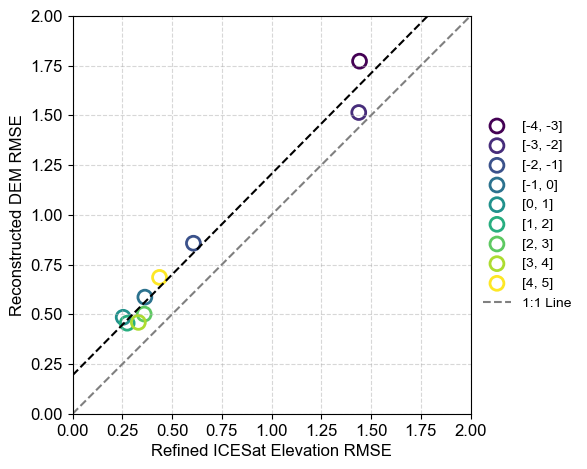

In [58]:
import matplotlib.pyplot as plt
import numpy as np

# ======================
# Font settings
# ======================
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.size'] = 12

# 数据

DEM_RMSE_list = [1.772, 1.514, 0.857, 0.586, 0.4848, 0.455, 0.501, 0.459, 0.6853]
ICESAT_RMSE_list = [1.442, 1.438,  0.607, 0.363, 0.254, 0.274, 0.3596,  0.3303,  0.4366]

x = np.array(ICESAT_RMSE_list)
y = np.array(DEM_RMSE_list)

# DEM_MAE_list = [1.5799, 1.180, 0.6079, 0.4195, 0.353, 0.332, 0.3643, 0.2993, 0.5367]
# ICESAT_MAE_list = [0.860, 0.9330,  0.320, 0.183, 0.1326, 0.1481, 0.2049, 0.1642,  0.2271]


# x = np.array(ICESAT_MAE_list)
# y = np.array(DEM_MAE_list)


# 图例名称
labels = [
    '[-4, -3]', '[-3, -2]', '[-2, -1]',
    '[-1, 0]', '[0, 1]', '[1, 2]',
    '[2, 3]', '[3, 4]', '[4, 5]'
]

# 渐变颜色
colors = plt.cm.viridis(np.linspace(0, 1, len(x)))

fig, ax = plt.subplots(figsize=(6, 6))

# ======================
# 空心圆散点
# ======================
for i in range(len(x)):
    ax.scatter(
        x[i],
        y[i],
        s=100,
        facecolors='none',
        edgecolors=colors[i],
        linewidths=2,
        marker='o',
        label=labels[i]
    )

# ======================
# 1:1 line
# ======================
ax.plot(
    [0, 2],
    [0, 2],
    '--',
    color='gray',
    linewidth=1.5,
    label='1:1 Line'
)

# ======================
# Linear fit
# ======================
coef = np.polyfit(x, y, 1)
poly1d_fn = np.poly1d(coef)

ax.plot(
    [0, 2],
    poly1d_fn([0, 2]),
    'k--',
    linewidth=1.5,
   # label=f'Fit: y={coef[0]:.2f}x+{coef[1]:.2f}'
)

# ======================
# Axis settings
# ======================
ax.set_xlim(0, 2)
ax.set_ylim(0, 2)

ax.set_xticks(np.arange(0, 2.01, 0.25))
ax.set_yticks(np.arange(0, 2.01, 0.25))
ax.set_xlabel('Refined ICESat Elevation RMSE')
ax.set_ylabel('Reconstructed DEM RMSE')

# 保持1:1比例
ax.set_aspect('equal')

# 图例
ax.legend(
    loc='upper left',
    fontsize=9,
    frameon=False,
    ncol=2
)

legend = ax.legend(
    loc='center left',          # 图例放在图外左侧
    bbox_to_anchor=(1, 0.5),    # 调整图例整体位置
    fontsize=10,                # 字体大小
    frameon=False,              # 去掉图例边框
    ncol=1                      # 单列排列
)

# 调整每个图例项的间距（垂直间距）
# for handle in legend.legendHandles:
#     handle.set_sizes([100])  # 调整图例点大小

# # 增大图例行间距
# legend._legend_box.sep = 15 


ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()